# Model Development & Tracking
## Stage 3 · baseline + advanced models, MLflow tracking & registry  <font color="red">[30 marks]</font>

- Each stage lists its **sub-tasks as a checklist**
- Complete every `# TODO`; implement the training logic in `src/train.py` (metrics helper provided in `src/evaluate.py`) and call it here.

**File ownership** — 
- *Provided:* `config.py`, `src/evaluate.py`
- *Provided to extend:* `src/train.py`. 
- *You create:* the cells below.

## Stage 3.1 — Baseline Model (Logistic Regression) <font color="red">[5 marks]</font>

- **3.1.1 — Logistic Regression baseline trained (Pipeline, imbalance handled) [3]** — `LogisticRegression(class_weight='balanced')` as a full Pipeline (preprocess + classify), fit on train.
- **3.1.2 — Baseline evaluated on validation [2]** — report imbalance-aware validation metrics (ROC-AUC / PR-AUC / recall).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import mlflow, config as cfg
# TODO 3.1.1: build & fit the LogReg baseline Pipeline (class_weight='balanced').
# TODO 3.1.2: evaluate it on the validation split and print the metrics.

# ===== SOLUTION START =====

# -----------------------------------------------------------------------------
# Imports and project paths
# -----------------------------------------------------------------------------
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

for _p in ['.', '..', 'src', '../src']:
    if os.path.isdir(_p) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))

try:
    import src.data_prep as dp
except ModuleNotFoundError:
    import data_prep as dp

try:
    from src.evaluate import compute_metrics, confusion
except ModuleNotFoundError:
    from evaluate import compute_metrics, confusion

# The two Stage 3 pipelines are defined once, in src/train.py, and reused here, so this
# notebook and the automated `python -m src.train` / retraining job build identical models.
from src.train import build_models, _log_model_compat

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 60)

TARGET = cfg.TARGET

# -----------------------------------------------------------------------------
# Stage 2 preparation: clean -> engineer -> stratified split (split happens FIRST)
# -----------------------------------------------------------------------------
raw = dp.load_raw()
clean_df = dp.clean(raw)
fe = dp.engineer_features(clean_df)

X_train, X_val, X_test, y_train, y_val, y_test = dp.get_splits(fe)
numeric, categorical = dp.get_feature_lists(fe)

print(f'train {X_train.shape}  val {X_val.shape}  test {X_test.shape}')
print(
    f'positive rate  train {y_train.mean():.4f}'
    f' | val {y_val.mean():.4f}'
    f' | test {y_test.mean():.4f}'
)
print(
    f'features: {len(numeric)} numeric + {len(categorical)} categorical'
    f' = {X_train.shape[1]}'
)

# Holds one entry per model: name -> {model, val_prob, metrics, confusion, params}
RESULTS = {}

# scale_pos_weight = negatives / positives from the TRAIN split only (used by XGBoost in 3.2).
neg = int((y_train == 0).sum())
pos = int((y_train == 1).sum())
scale_pos_weight = neg / pos
MODELS = build_models(numeric, categorical, scale_pos_weight)

# -----------------------------------------------------------------------------
# 3.1.1  Baseline model: Logistic Regression inside a single Pipeline
# -----------------------------------------------------------------------------
# One Pipeline = preprocessor + classifier, so the preprocessor is fitted on the
# TRAIN split only (no leakage), and class_weight='balanced' handles the ~10:1
# imbalance by re-weighting the loss instead of discarding majority rows.
logreg_pipe = MODELS['logistic_regression']
print('baseline classifier:', logreg_pipe.named_steps['classify'])

logreg_pipe.fit(X_train, y_train)

n_features_out = (
    logreg_pipe.named_steps['preprocess'].transform(X_train.head(1)).shape[1]
)
print('\nbaseline pipeline fitted on train only:', [s[0] for s in logreg_pipe.steps])
print('transformed feature count:', n_features_out)

# -----------------------------------------------------------------------------
# 3.1.2  Evaluate the baseline on the VALIDATION split
# -----------------------------------------------------------------------------
val_prob_lr = logreg_pipe.predict_proba(X_val)[:, 1]
metrics_lr = compute_metrics(y_val, val_prob_lr)
cm_lr = confusion(y_val, val_prob_lr)

RESULTS['logistic_regression'] = {
    'model': logreg_pipe,
    'val_prob': val_prob_lr,
    'metrics': metrics_lr,
    'confusion': cm_lr,
    'params': {
        'model_type': 'LogisticRegression',
        'class_weight': 'balanced',
        'max_iter': 2000,
        'solver': 'lbfgs',
        'random_state': cfg.RANDOM_STATE,
    },
}

print('\n--- 3.1.2 Logistic Regression | validation metrics (threshold = 0.5) ---')
for k, v in metrics_lr.items():
    print(f'  {k:<10}: {v:.4f}')
print('  confusion :', cm_lr)

pr_lift = metrics_lr['pr_auc'] / y_val.mean()
print(
    f'\n  PR-AUC {metrics_lr["pr_auc"]:.4f} vs a random baseline of'
    f' {y_val.mean():.4f} ({pr_lift:.2f}x lift)'
)
print(
    f'  recall {metrics_lr["recall"]:.4f} catches {cm_lr["tp"]:,}'
    f' of {cm_lr["tp"] + cm_lr["fn"]:,} readmissions'
)
print(
    f'  a majority-class model would score accuracy {1 - y_val.mean():.4f}'
    ' with recall 0.0000'
)
print('  -> accuracy is not a usable selection metric here')

# ===== SOLUTION END =====

train (44782, 37)  val (11196, 37)  test (13995, 37)
positive rate  train 0.0897 | val 0.0897 | test 0.0897
features: 12 numeric + 25 categorical = 37
baseline classifier: LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)



baseline pipeline fitted on train only: ['preprocess', 'classify']
transformed feature count: 172

--- 3.1.2 Logistic Regression | validation metrics (threshold = 0.5) ---
  roc_auc   : 0.6528
  pr_auc    : 0.1715
  f1        : 0.2268
  recall    : 0.5428
  precision : 0.1433
  accuracy  : 0.6681
  confusion : {'tn': 6935, 'fp': 3257, 'fn': 459, 'tp': 545}

  PR-AUC 0.1715 vs a random baseline of 0.0897 (1.91x lift)
  recall 0.5428 catches 545 of 1,004 readmissions
  a majority-class model would score accuracy 0.9103 with recall 0.0000
  -> accuracy is not a usable selection metric here


## Stage 3.2 — Advanced Model (XGBoost) <font color="red">[8 marks]</font>

- **3.2.1 — XGBoost trained (Pipeline, `scale_pos_weight` imbalance handled) [5]** — XGBoost with `scale_pos_weight = neg/pos` as a full Pipeline, fit on train.
- **3.2.2 — Advanced model evaluated on validation [3]** — report the same validation metrics for comparison with the baseline.

In [2]:
# TODO 3.2.1: build & fit the XGBoost Pipeline (scale_pos_weight = neg/pos).
# TODO 3.2.2: evaluate it on the validation split and print the metrics.

# ===== SOLUTION START =====

# -----------------------------------------------------------------------------
# 3.2.1  Advanced model: XGBoost inside the same Pipeline shape
# -----------------------------------------------------------------------------
# scale_pos_weight = negatives / positives is XGBoost's imbalance lever: it
# scales the gradient of the positive class so the ~10:1 skew does not collapse
# every split towards the majority class. It is computed from TRAIN ONLY, because
# using the full frame would leak the val/test class balance into a
# hyper-parameter.
# (neg / pos computed in the 3.1 cell, before either model was built)
print(
    f'train negatives {neg:,} / positives {pos:,}'
    f' -> scale_pos_weight = {scale_pos_weight:.4f}'
)
print('cfg.XGB_PARAMS:', cfg.XGB_PARAMS)

xgb_pipe = MODELS['xgboost']

xgb_pipe.fit(X_train, y_train)
print('\nadvanced pipeline fitted on train only:', [s[0] for s in xgb_pipe.steps])

# -----------------------------------------------------------------------------
# 3.2.2  Evaluate the advanced model on the VALIDATION split
# -----------------------------------------------------------------------------
val_prob_xgb = xgb_pipe.predict_proba(X_val)[:, 1]
metrics_xgb = compute_metrics(y_val, val_prob_xgb)
cm_xgb = confusion(y_val, val_prob_xgb)

RESULTS['xgboost'] = {
    'model': xgb_pipe,
    'val_prob': val_prob_xgb,
    'metrics': metrics_xgb,
    'confusion': cm_xgb,
    'params': {
        'model_type': 'XGBClassifier',
        'scale_pos_weight': round(scale_pos_weight, 4),
        **cfg.XGB_PARAMS,
    },
}

print('\n--- 3.2.2 XGBoost | validation metrics (threshold = 0.5) ---')
for k, v in metrics_xgb.items():
    print(f'  {k:<10}: {v:.4f}   ({v - metrics_lr[k]:+.4f} vs baseline)')
print('  confusion :', cm_xgb)
print(
    f'\n  PR-AUC  {metrics_xgb["pr_auc"]:.4f}'
    f' vs {metrics_lr["pr_auc"]:.4f} baseline'
)
print(
    f'  ROC-AUC {metrics_xgb["roc_auc"]:.4f}'
    f' vs {metrics_lr["roc_auc"]:.4f} baseline'
)

# ===== SOLUTION END =====

train negatives 40,764 / positives 4,018 -> scale_pos_weight = 10.1453
cfg.XGB_PARAMS: {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1, 'subsample': 0.9, 'colsample_bytree': 0.9, 'random_state': 42, 'n_jobs': -1, 'eval_metric': 'auc', 'tree_method': 'hist'}



advanced pipeline fitted on train only: ['preprocess', 'classify']



--- 3.2.2 XGBoost | validation metrics (threshold = 0.5) ---
  roc_auc   : 0.6480   (-0.0048 vs baseline)
  pr_auc    : 0.1754   (+0.0039 vs baseline)
  f1        : 0.2281   (+0.0013 vs baseline)
  recall    : 0.4502   (-0.0926 vs baseline)
  precision : 0.1528   (+0.0095 vs baseline)
  accuracy  : 0.7268   (+0.0587 vs baseline)
  confusion : {'tn': 7685, 'fp': 2507, 'fn': 552, 'tp': 452}

  PR-AUC  0.1754 vs 0.1715 baseline
  ROC-AUC 0.6480 vs 0.6528 baseline


## Stage 3.3 — Model Evaluation <font color="red">[5 marks]</font>

- **3.3.1 — Imbalance-aware metrics + model selection [3]** — ROC-AUC, PR-AUC, recall, precision, F1 for both models in a comparison table; select on ROC-AUC.
- **3.3.2 — Plots + interpretation (why accuracy misleads) [2]** — ROC + confusion plots; explain why accuracy is misleading at ~9% prevalence.

--- 3.3.1 validation metric comparison (threshold = 0.5) ---


,roc_auc,pr_auc,recall,precision,f1,accuracy,tp,fn,fp
model,,,,,,,,,
logistic_regression,0.6528,0.1715,0.5428,0.1433,0.2268,0.6681,545,459,3257
xgboost,0.6480,0.1754,0.4502,0.1528,0.2281,0.7268,452,552,2507


selection criterion : highest validation ROC-AUC
selected model      : logistic_regression  (ROC-AUC 0.6528)
runner-up           : xgboost 0.6480


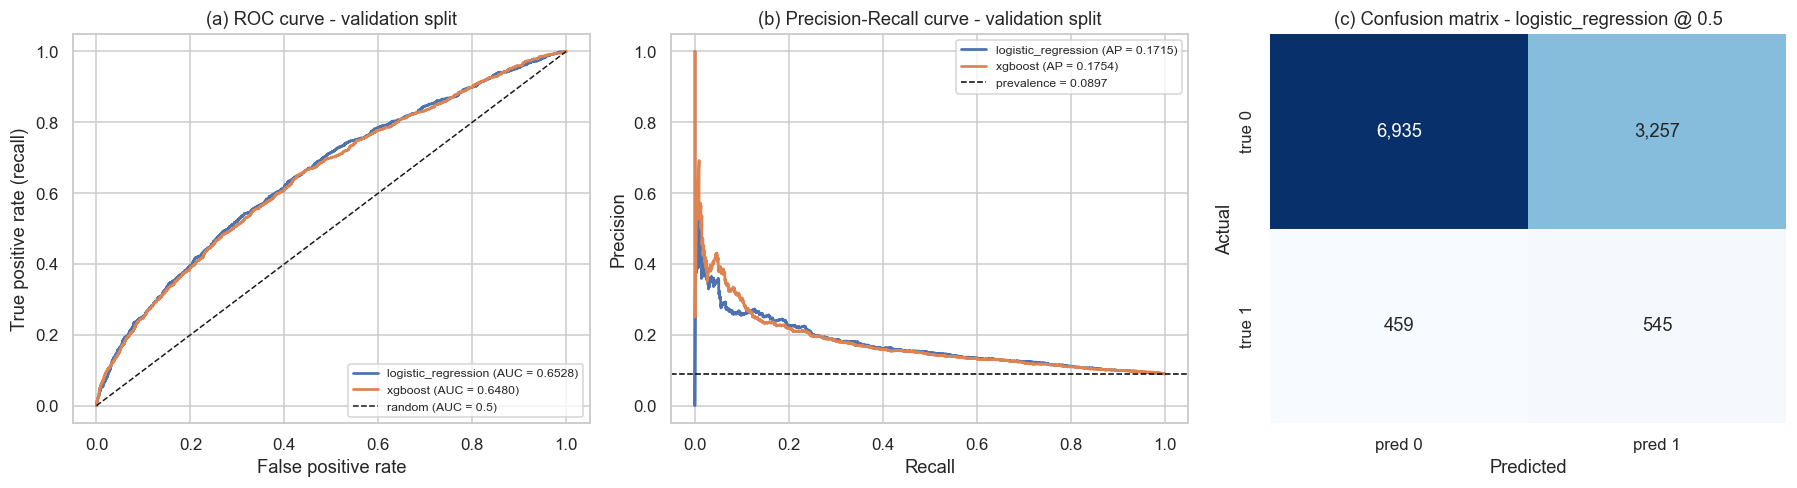


threshold sweep for the selected model (operating point is a business choice):


,alerts,alert_rate,recall,precision,f1,accuracy,missed_readmissions_fn
threshold,,,,,,,
0.3,10500,0.9378,0.9721,0.0930,0.1697,0.1468,28
0.4,7402,0.6611,0.8078,0.1096,0.1930,0.3941,193
0.5,3802,0.3396,0.5428,0.1433,0.2268,0.6681,459
0.6,1681,0.1501,0.3078,0.1838,0.2302,0.8154,695
0.7,616,0.0550,0.1574,0.2565,0.1951,0.8835,846



INTERPRETATION - why accuracy misleads at this prevalence

  1. The validation split holds 1,004 positives in 11,196 patients (8.97% prevalence). A
     model that predicts "never readmitted" for everyone scores accuracy 0.9103 while
     finding ZERO at-risk patients, so a high accuracy number can coexist with a clinically
     worthless model.

  2. The selected model scores accuracy 0.6681, which is -0.2422 against that do-nothing
     baseline, yet it recovers recall 0.5428: 545 true readmissions found and 459 missed.
     Accuracy cannot see that trade because the 10,192 negatives dominate the ratio.

  3. Imbalance-aware metrics are used instead: ROC-AUC for threshold-free ranking (the
     selection metric), PR-AUC against the 0.0897 prevalence baseline for positive-class
     quality, and recall / precision at an explicit threshold for the operational decision.

  4. Class weighting does the rest. By re-weighting the loss (class_weight='balanced' /
     scale_pos_weight=10.145

In [3]:
# TODO 3.3.1: build the metric comparison table and select the best model on ROC-AUC.
# TODO 3.3.2: plot ROC + confusion for the best model; add a written interpretation.

# ===== SOLUTION START =====

import textwrap

from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix

# -----------------------------------------------------------------------------
# 3.3.1  Imbalance-aware metric comparison and model selection on ROC-AUC
# -----------------------------------------------------------------------------
METRIC_ORDER = ['roc_auc', 'pr_auc', 'recall', 'precision', 'f1', 'accuracy']

comparison = (
    pd.DataFrame({name: res['metrics'] for name, res in RESULTS.items()})
    .T[METRIC_ORDER]
    .rename_axis('model')
)
for count_key in ['tp', 'fn', 'fp']:
    comparison[count_key] = [
        RESULTS[name]['confusion'][count_key] for name in comparison.index
    ]

print('--- 3.3.1 validation metric comparison (threshold = 0.5) ---')
display(comparison)

# The selection criterion is fixed in advance: highest validation ROC-AUC.
best_name = comparison['roc_auc'].idxmax()
best_model = RESULTS[best_name]['model']
best_prob = RESULTS[best_name]['val_prob']
best_cm = RESULTS[best_name]['confusion']

runner_up = ', '.join(
    f'{name} {comparison.loc[name, "roc_auc"]:.4f}'
    for name in comparison.index
    if name != best_name
)
print('selection criterion : highest validation ROC-AUC')
print(
    f'selected model      : {best_name}'
    f'  (ROC-AUC {comparison.loc[best_name, "roc_auc"]:.4f})'
)
print('runner-up           :', runner_up)

# -----------------------------------------------------------------------------
# 3.3.2  ROC, Precision-Recall and confusion plots
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.6))

# (a) ROC curves for both models.
for name, res in RESULTS.items():
    fpr, tpr, _ = roc_curve(y_val, res['val_prob'])
    ax[0].plot(
        fpr,
        tpr,
        lw=1.8,
        label=f'{name} (AUC = {res["metrics"]["roc_auc"]:.4f})',
    )
ax[0].plot([0, 1], [0, 1], 'k--', lw=1, label='random (AUC = 0.5)')
ax[0].set_title('(a) ROC curve - validation split')
ax[0].set_xlabel('False positive rate')
ax[0].set_ylabel('True positive rate (recall)')
ax[0].legend(loc='lower right', fontsize=8)

# (b) Precision-Recall curves - the honest view at ~9% prevalence.
for name, res in RESULTS.items():
    prec, rec, _ = precision_recall_curve(y_val, res['val_prob'])
    ax[1].plot(
        rec,
        prec,
        lw=1.8,
        label=f'{name} (AP = {res["metrics"]["pr_auc"]:.4f})',
    )
ax[1].axhline(
    y_val.mean(),
    ls='--',
    color='black',
    lw=1,
    label=f'prevalence = {y_val.mean():.4f}',
)
ax[1].set_title('(b) Precision-Recall curve - validation split')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].legend(loc='upper right', fontsize=8)

# (c) Confusion matrix of the selected model at threshold 0.5.
cm = confusion_matrix(y_val, (best_prob >= 0.5).astype(int))
sns.heatmap(
    cm,
    annot=True,
    fmt=',d',
    cmap='Blues',
    cbar=False,
    ax=ax[2],
    xticklabels=['pred 0', 'pred 1'],
    yticklabels=['true 0', 'true 1'],
)
ax[2].set_title(f'(c) Confusion matrix - {best_name} @ 0.5')
ax[2].set_xlabel('Predicted')
ax[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# Threshold sweep: recall against the alert budget
# -----------------------------------------------------------------------------
sweep_rows = []
for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    m = compute_metrics(y_val, best_prob, threshold=thr)
    c = confusion(y_val, best_prob, threshold=thr)
    alerts = c['tp'] + c['fp']
    sweep_rows.append({
        'threshold': thr,
        'alerts': alerts,
        'alert_rate': round(alerts / len(y_val), 4),
        'recall': m['recall'],
        'precision': m['precision'],
        'f1': m['f1'],
        'accuracy': m['accuracy'],
        'missed_readmissions_fn': c['fn'],
    })

print('\nthreshold sweep for the selected model (operating point is a business choice):')
display(pd.DataFrame(sweep_rows).set_index('threshold'))

# -----------------------------------------------------------------------------
# Written interpretation: why accuracy misleads at this prevalence
# -----------------------------------------------------------------------------
majority_acc = 1 - y_val.mean()
best_acc = comparison.loc[best_name, 'accuracy']
best_recall = comparison.loc[best_name, 'recall']
xgb_weight = RESULTS['xgboost']['params']['scale_pos_weight']

interpretation = [
    (
        f'The validation split holds {int(y_val.sum()):,} positives in '
        f'{len(y_val):,} patients ({y_val.mean():.2%} prevalence). A model that '
        'predicts "never readmitted" for everyone scores accuracy '
        f'{majority_acc:.4f} while finding ZERO at-risk patients, so a high '
        'accuracy number can coexist with a clinically worthless model.'
    ),
    (
        f'The selected model scores accuracy {best_acc:.4f}, which is '
        f'{best_acc - majority_acc:+.4f} against that do-nothing baseline, yet '
        f'it recovers recall {best_recall:.4f}: {best_cm["tp"]:,} true '
        f'readmissions found and {best_cm["fn"]:,} missed. Accuracy cannot see '
        f'that trade because the {int((y_val == 0).sum()):,} negatives dominate '
        'the ratio.'
    ),
    (
        'Imbalance-aware metrics are used instead: ROC-AUC for threshold-free '
        'ranking (the selection metric), PR-AUC against the '
        f'{y_val.mean():.4f} prevalence baseline for positive-class quality, '
        'and recall / precision at an explicit threshold for the operational '
        'decision.'
    ),
    (
        'Class weighting does the rest. By re-weighting the loss '
        f"(class_weight='balanced' / scale_pos_weight={xgb_weight}), both "
        'models trade precision for recall on purpose, because a missed '
        'readmission costs far more than one unnecessary follow-up call. That '
        'is why precision looks low while recall is high.'
    ),
    (
        'Plot (a) ranks the models, plot (b) is the honest view at this '
        f'prevalence where both curves sit above the {y_val.mean():.4f} random '
        'line, and plot (c) shows the actual patient counts behind the chosen '
        'threshold.'
    ),
]

print('\nINTERPRETATION - why accuracy misleads at this prevalence')
for i, paragraph in enumerate(interpretation, start=1):
    print()
    print(textwrap.fill(
        paragraph,
        width=92,
        initial_indent=f'  {i}. ',
        subsequent_indent='     ',
    ))

# ===== SOLUTION END =====

## Stage 3.4 — MLflow Experiment Tracking <font color="red">[7 marks]</font>

- **3.4.1 — Both runs logged with params + metrics + model [4]** — set tracking URI + experiment; for each model log params, metrics and the model artefact.
- **3.4.2 — Runs compared (search_runs table) [3]** — compare the runs with `mlflow.search_runs(...)` and state the selection criterion.

In [4]:
# TODO 3.4.1: log both runs (params + metrics + model) to an MLflow experiment.
# TODO 3.4.2: compare the runs with mlflow.search_runs(...).

# ===== SOLUTION START =====

import mlflow.sklearn
from mlflow.models import infer_signature

# -----------------------------------------------------------------------------
# 3.4.1  Tracking URI and experiment
# -----------------------------------------------------------------------------
# cfg.MLFLOW_TRACKING_URI is sqlite:///mlflow.db - a database backend is required
# for the Model Registry used in Stage 3.5 (a plain file:// store cannot register).
import logging
for _name in ('alembic', 'mlflow.store.db.utils', 'mlflow.tracking.fluent'):
    logging.getLogger(_name).setLevel(logging.WARNING)   # hide one-off DB migration chatter

import contextlib, io
mlflow.set_tracking_uri(cfg.MLFLOW_TRACKING_URI)
with contextlib.redirect_stderr(io.StringIO()):   # first use creates the SQLite schema
    mlflow.set_experiment(cfg.MLFLOW_EXPERIMENT)
    mlflow.tracking.MlflowClient().search_registered_models()   # ...and the registry tables

print('tracking URI :', mlflow.get_tracking_uri())
print('experiment   :', cfg.MLFLOW_EXPERIMENT)

input_example = X_train.head(5)

# src/train.py::_log_model_compat handles the mlflow 2/3 log_model signature difference and
# pins serialization_format='cloudpickle' (skops refuses the numpy.dtype objects held by a
# fitted ColumnTransformer).
log_model_compat = _log_model_compat


for name, res in RESULTS.items():
    with mlflow.start_run(run_name=name) as run:
        # Params: model hyper-parameters, imbalance handling, data fingerprint.
        mlflow.log_params({str(k): str(v) for k, v in res['params'].items()})
        mlflow.log_params({
            'random_state': cfg.RANDOM_STATE,
            'n_train': len(X_train),
            'n_val': len(X_val),
            'n_test': len(X_test),
            'n_raw_features': X_train.shape[1],
            'n_numeric': len(numeric),
            'n_categorical': len(categorical),
            'train_pos_rate': round(float(y_train.mean()), 4),
            'imbalance_handling': res['params'].get(
                'class_weight',
                res['params'].get('scale_pos_weight'),
            ),
        })

        # Metrics: imbalance-aware validation metrics plus raw confusion counts.
        mlflow.log_metrics({
            f'val_{k}': float(v) for k, v in res['metrics'].items()
        })
        mlflow.log_metrics({
            f'val_{k}': float(v) for k, v in res['confusion'].items()
        })

        mlflow.set_tags({
            'stage': '3',
            'split': 'validation',
            'selection_metric': 'val_roc_auc',
            'model_family': res['params']['model_type'],
        })

        # The artefact is the FULL pipeline, so preprocessing ships with the model.
        log_model_compat(
            res['model'],
            'model',
            signature=infer_signature(
                input_example, res['model'].predict_proba(input_example)[:, 1]),
            input_example=input_example,
        )

        res['run_id'] = run.info.run_id
        print(
            f'logged {name:<20} run_id={run.info.run_id}'
            f'  val_roc_auc={res["metrics"]["roc_auc"]:.4f}'
        )

# -----------------------------------------------------------------------------
# 3.4.2  Compare the runs with search_runs
# -----------------------------------------------------------------------------
try:
    runs = mlflow.search_runs(
        experiment_names=[cfg.MLFLOW_EXPERIMENT],
        filter_string="attributes.status = 'FINISHED'",
        order_by=['metrics.val_roc_auc DESC'],
    )
except TypeError:
    # Older mlflow versions accept experiment_ids only.
    experiment = mlflow.get_experiment_by_name(cfg.MLFLOW_EXPERIMENT)
    runs = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        filter_string="attributes.status = 'FINISHED'",
        order_by=['metrics.val_roc_auc DESC'],
    )

show_cols = [
    'run_id',
    'tags.mlflow.runName',
    'metrics.val_roc_auc',
    'metrics.val_pr_auc',
    'metrics.val_recall',
    'metrics.val_precision',
    'metrics.val_f1',
    'metrics.val_accuracy',
    'params.model_type',
    'params.imbalance_handling',
    'start_time',
    'status',
]

print(f'\n--- 3.4.2 search_runs comparison ({len(runs)} FINISHED runs in the experiment) ---')
display(runs[[c for c in show_cols if c in runs.columns]])

# The decision is reproduced from the tracking store alone, not from in-memory results.
store_best = runs.iloc[0]
assert store_best['run_id'] == RESULTS[best_name]['run_id'], 'tracking store disagrees with 3.3.1'
print('tracking-store winner :', store_best['tags.mlflow.runName'], store_best['run_id'])

print(
    '\nselection criterion : highest metrics.val_roc_auc'
    ' (runs are ordered by it above).'
)
print(
    'ROC-AUC is used for selection because it is threshold-free, so the'
    ' comparison does not depend'
)
print(
    'on an operating point that has not been chosen yet. PR-AUC and recall are'
    ' logged alongside it'
)
print(
    'as the imbalance-aware checks, and accuracy is logged only to show how'
    f' little it separates the'
)
print(f'models at {y_val.mean():.2%} prevalence.')
print(
    f'best run by val_roc_auc : {best_name}'
    f' (run_id {RESULTS[best_name]["run_id"]})'
)

# ===== SOLUTION END =====

tracking URI : sqlite:///mlflow.db
experiment   : hospital_readmission


logged logistic_regression  run_id=f8be9b08313a445f8bc44add49d7c84c  val_roc_auc=0.6528


logged xgboost              run_id=45e5b025ddd74512b954cba4cb190d06  val_roc_auc=0.6480

--- 3.4.2 search_runs comparison (2 FINISHED runs in the experiment) ---


,run_id,tags.mlflow.runName,metrics.val_roc_auc,metrics.val_pr_auc,metrics.val_recall,metrics.val_precision,metrics.val_f1,metrics.val_accuracy,params.model_type,params.imbalance_handling,start_time,status
0,f8be9b08313a445f8bc44add49d7c84c,logistic_regression,0.6528,0.1715,0.5428,0.1433,0.2268,0.6681,LogisticRegression,balanced,2026-10-20 06:53:52.220000+00:00,FINISHED
1,45e5b025ddd74512b954cba4cb190d06,xgboost,0.6480,0.1754,0.4502,0.1528,0.2281,0.7268,XGBClassifier,10.1453,2026-10-20 06:54:00.301000+00:00,FINISHED


tracking-store winner : logistic_regression f8be9b08313a445f8bc44add49d7c84c

selection criterion : highest metrics.val_roc_auc (runs are ordered by it above).
ROC-AUC is used for selection because it is threshold-free, so the comparison does not depend
on an operating point that has not been chosen yet. PR-AUC and recall are logged alongside it
as the imbalance-aware checks, and accuracy is logged only to show how little it separates the
models at 8.97% prevalence.
best run by val_roc_auc : logistic_regression (run_id f8be9b08313a445f8bc44add49d7c84c)


## Stage 3.5 — Model Registry & Versioning <font color="red">[5 marks]</font>

- **3.5.1 — Best model registered in the MLflow Model Registry [2]** — `mlflow.register_model` for the best model.
- **3.5.2 — Promotion to production alias + version history [3]** — promote to the `production` alias and show the version history.

Successfully registered model 'readmission_classifier'.
2026/10/20 12:24:05 WARNING mlflow.tracking._model_registry.fluent: Run with id f8be9b08313a445f8bc44add49d7c84c has no artifacts at artifact path 'model', registering model based on models:/m-7414abaaf9ef40048a813df523d4b6e5 instead


registered readmission_classifier version 1 from run f8be9b08313a445f8bc44add49d7c84c (logistic_regression)


version status : READY


Created version '1' of model 'readmission_classifier'.


promoted version 1 via alias 'production'

--- 3.5.2 version history for readmission_classifier ---


,name,version,run_id,status,aliases,stage,val_roc_auc,created
0,readmission_classifier,1,f8be9b08313a445f8bc44add49d7c84c,READY,production,None,0.6528,2026-10-20 06:54:05.541


current production alias -> 1



loaded models:/readmission_classifier@production and scored the test split (first and only use):
  test_roc_auc   : 0.6454
  test_pr_auc    : 0.1666
  test_f1        : 0.2186
  test_recall    : 0.5235
  test_precision : 0.1382
  test_accuracy  : 0.6645
  test confusion : {'tn': 8642, 'fp': 4098, 'fn': 598, 'tp': 657}

artefacts saved to C:\Users\rane5\OneDrive\Desktop\Capstone Project\Capstone Project\MLOps 1 - Starter\artifacts : ['best_model.pkl', 'input_columns.json', 'metrics.json', 'reference_sample.csv']


MLflow UI screenshot -> mlflow_experiment_runs.png


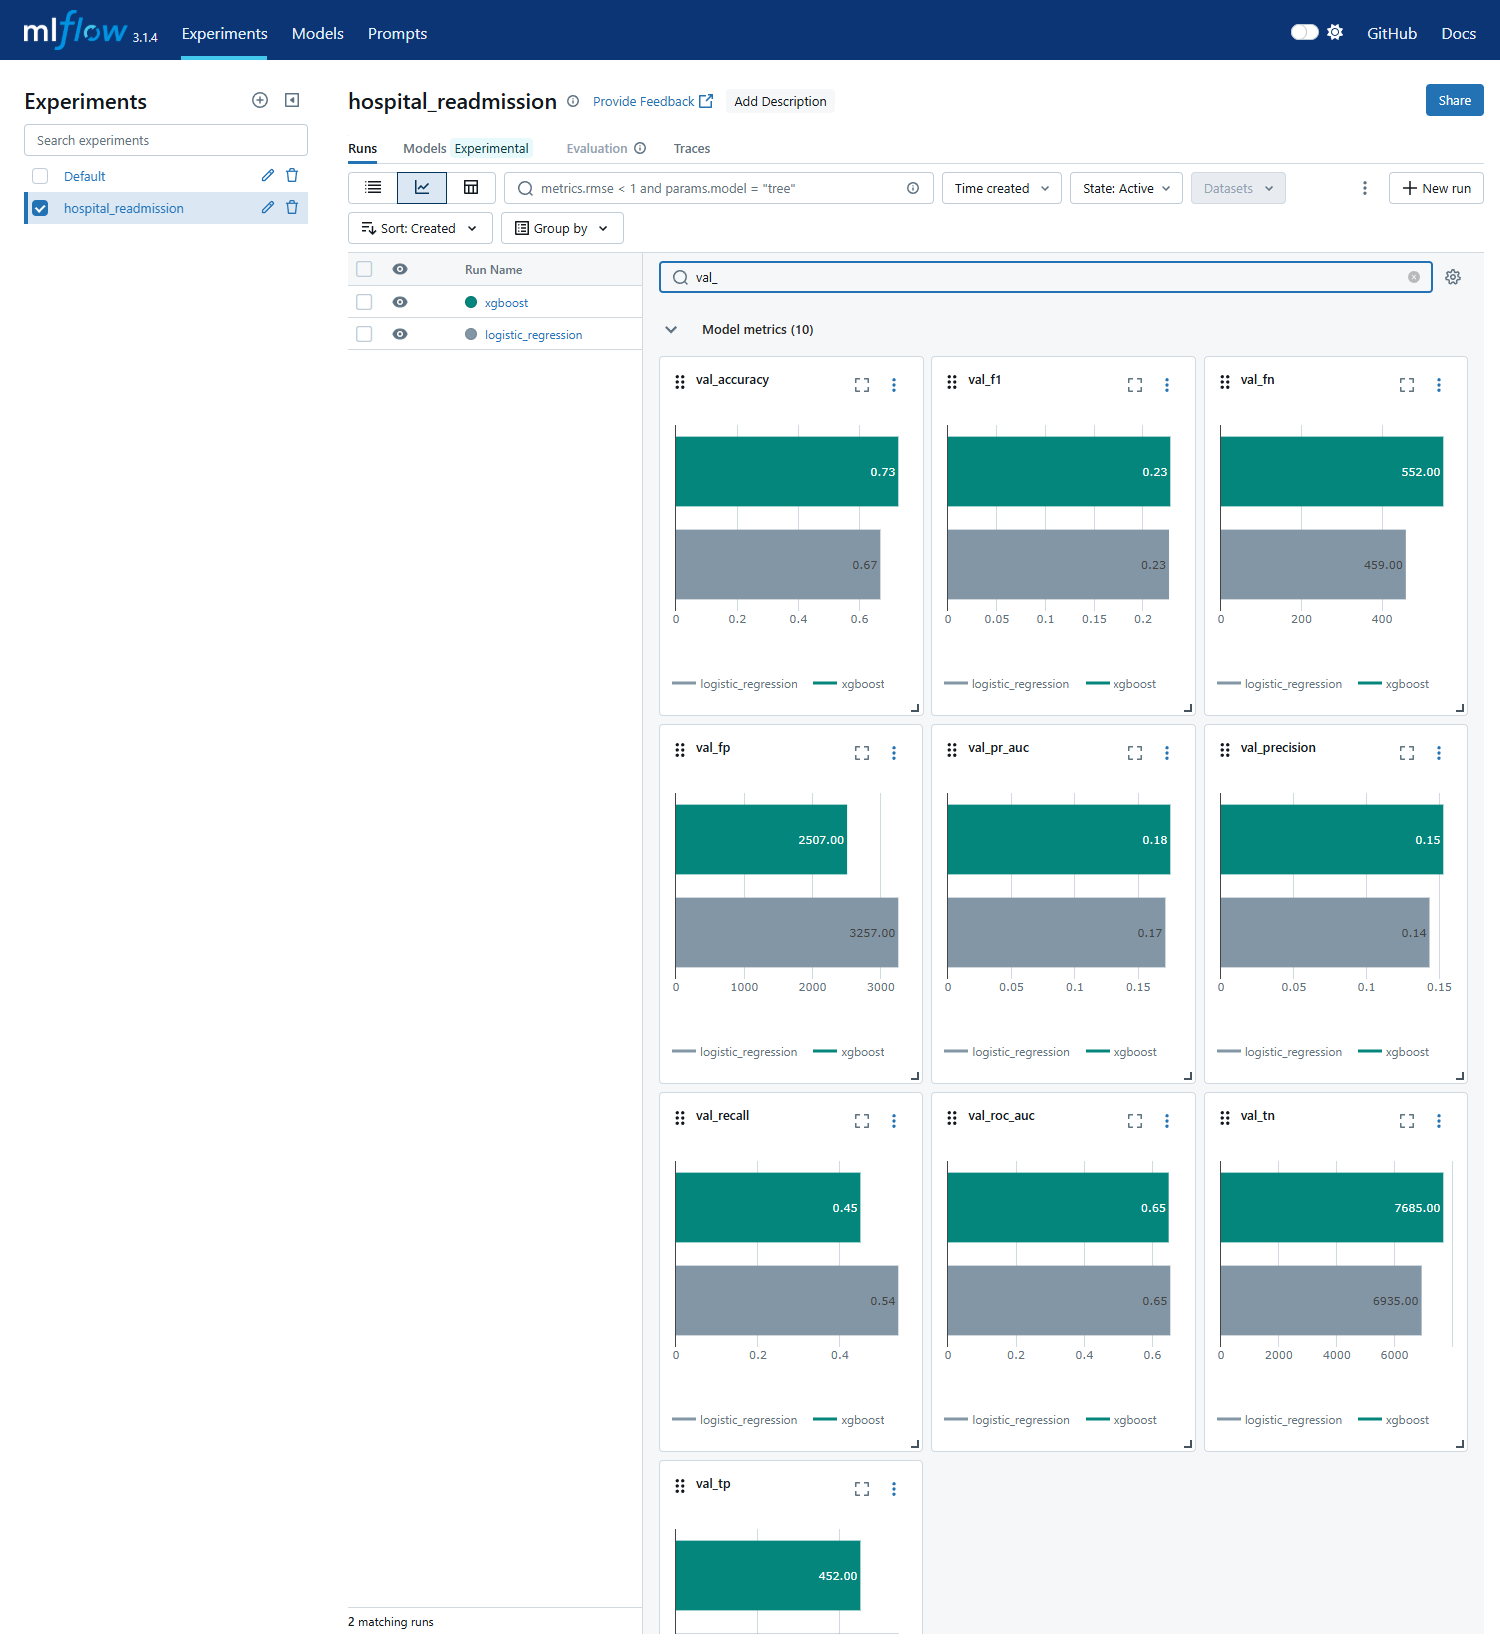

MLflow UI screenshot -> mlflow_registry_versions.png


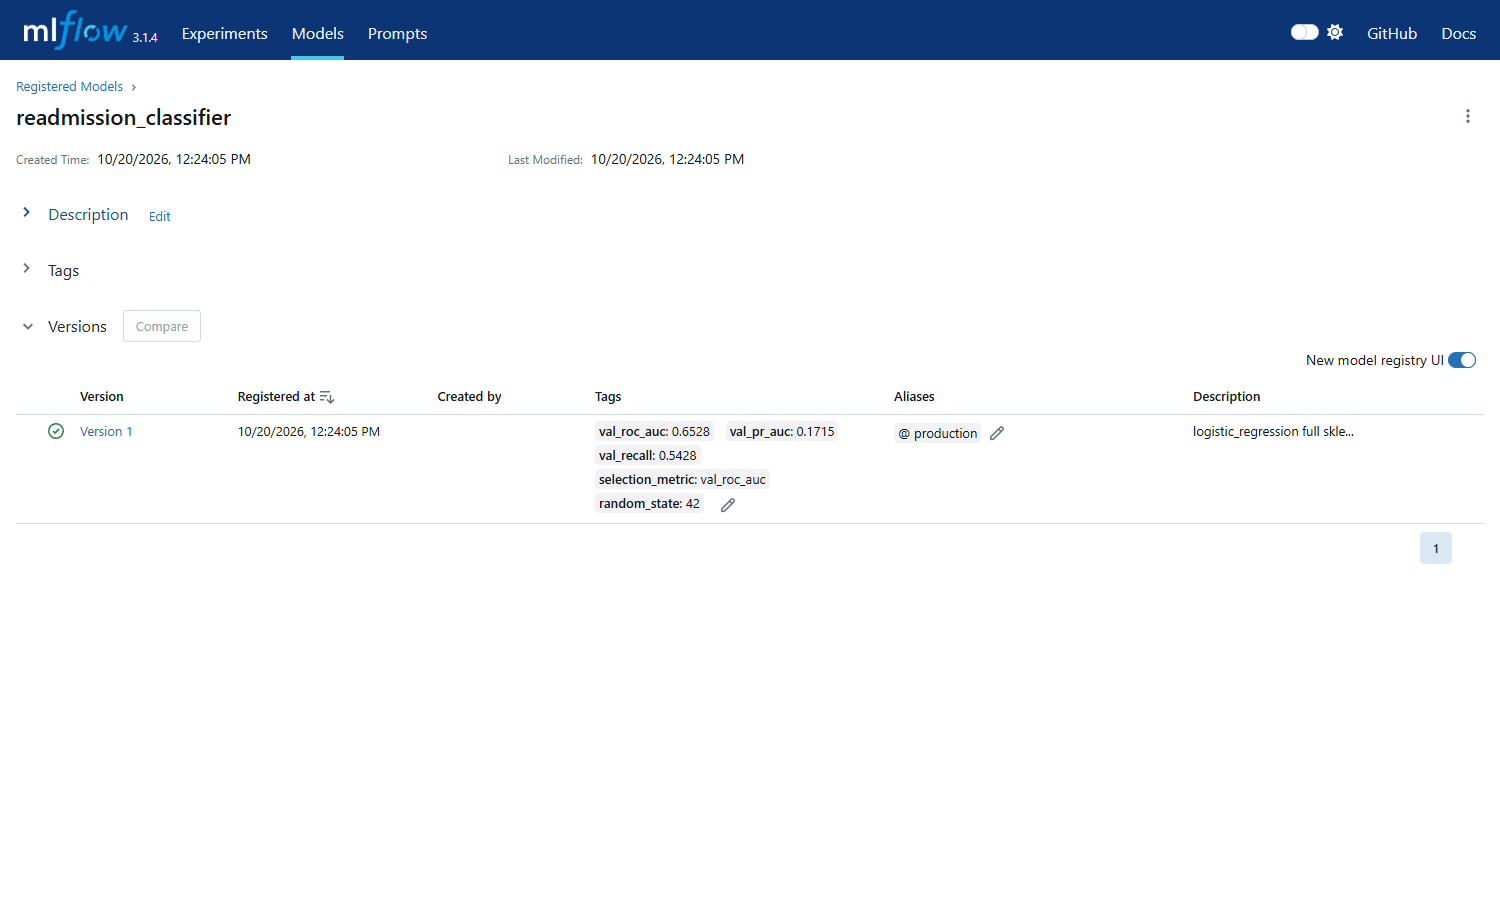

In [5]:
# TODO 3.5.1: register the best model (by val ROC-AUC) with mlflow.register_model.
# TODO 3.5.2: promote it to the 'production' alias and print the version history.

# ===== SOLUTION START =====

import time

from mlflow.tracking import MlflowClient

client = MlflowClient()
best_run = RESULTS[best_name]['run_id']
model_uri = f'runs:/{best_run}/model'

# -----------------------------------------------------------------------------
# 3.5.1  Register the selected model from its run URI
# -----------------------------------------------------------------------------
mv = mlflow.register_model(model_uri=model_uri, name=cfg.REGISTERED_MODEL)
print(
    f'registered {cfg.REGISTERED_MODEL} version {mv.version}'
    f' from run {best_run} ({best_name})'
)

status = None
for _ in range(30):
    status = client.get_model_version(cfg.REGISTERED_MODEL, mv.version).status
    if status == 'READY':
        break
    time.sleep(1)
print('version status :', status)

# Provenance recorded on the version itself, so the registry is self-documenting.
imbalance_note = (
    RESULTS[best_name]['params'].get('class_weight') or 'scale_pos_weight'
)
client.update_model_version(
    name=cfg.REGISTERED_MODEL,
    version=mv.version,
    description=(
        f'{best_name} full sklearn Pipeline (preprocessor + classifier). '
        'Selected on validation ROC-AUC = '
        f'{RESULTS[best_name]["metrics"]["roc_auc"]:.4f}. '
        f'Imbalance handled via {imbalance_note}.'
    ),
)

version_tags = {
    'val_roc_auc': RESULTS[best_name]['metrics']['roc_auc'],
    'val_pr_auc': RESULTS[best_name]['metrics']['pr_auc'],
    'val_recall': RESULTS[best_name]['metrics']['recall'],
    'selection_metric': 'val_roc_auc',
    'random_state': cfg.RANDOM_STATE,
}
for key, value in version_tags.items():
    client.set_model_version_tag(
        cfg.REGISTERED_MODEL, mv.version, key, str(value)
    )

# -----------------------------------------------------------------------------
# 3.5.2  Promote to the 'production' alias and show the version history
# -----------------------------------------------------------------------------
try:
    client.set_registered_model_alias(
        cfg.REGISTERED_MODEL, 'production', mv.version
    )
    promoted_via = "alias 'production'"
except AttributeError:
    # mlflow < 2.9 has no aliases, so fall back to the legacy stage API.
    client.transition_model_version_stage(
        cfg.REGISTERED_MODEL,
        mv.version,
        stage='Production',
        archive_existing_versions=True,
    )
    promoted_via = "stage 'Production'"
print(f'promoted version {mv.version} via {promoted_via}')

# search_model_versions does not populate aliases, so each version is re-read individually.
versions = [client.get_model_version(cfg.REGISTERED_MODEL, v.version)
            for v in client.search_model_versions(f"name='{cfg.REGISTERED_MODEL}'")]
history = pd.DataFrame([
    {
        'name': v.name,
        'version': int(v.version),
        'run_id': v.run_id,
        'status': v.status,
        'aliases': ', '.join(getattr(v, 'aliases', []) or []),
        'stage': getattr(v, 'current_stage', ''),
        'val_roc_auc': (v.tags or {}).get('val_roc_auc', ''),
        'created': pd.to_datetime(v.creation_timestamp, unit='ms'),
    }
    for v in versions
]).sort_values('version', ascending=False)

print(f'\n--- 3.5.2 version history for {cfg.REGISTERED_MODEL} ---')
display(history)

if hasattr(client, 'get_model_version_by_alias'):
    current = client.get_model_version_by_alias(
        cfg.REGISTERED_MODEL, 'production'
    ).version
else:
    current = promoted_via
print('current production alias ->', current)

# -----------------------------------------------------------------------------
# Load back BY ALIAS and touch the held-out test split exactly once
# -----------------------------------------------------------------------------
prod_uri = f'models:/{cfg.REGISTERED_MODEL}@production'
try:
    prod_model = mlflow.sklearn.load_model(prod_uri)
except Exception:
    # Stage-based fallback for older mlflow versions.
    prod_uri = f'models:/{cfg.REGISTERED_MODEL}/Production'
    prod_model = mlflow.sklearn.load_model(prod_uri)

test_prob = prod_model.predict_proba(X_test)[:, 1]
test_metrics = compute_metrics(y_test, test_prob)
test_cm = confusion(y_test, test_prob)

print(f'\nloaded {prod_uri} and scored the test split (first and only use):')
for k, v in test_metrics.items():
    print(f'  test_{k:<10}: {v:.4f}')
print('  test confusion :', test_cm)

# Attach the test metrics to the winning run for a complete audit trail.
with mlflow.start_run(run_id=best_run):
    mlflow.log_metrics({f'test_{k}': float(v) for k, v in test_metrics.items()})
    mlflow.log_metrics({f'test_{k}': float(v) for k, v in test_cm.items()})
    mlflow.set_tags({
        'registered_model': cfg.REGISTERED_MODEL,
        'registered_version': str(mv.version),
        'alias': 'production',
    })

# -----------------------------------------------------------------------------
# Artefacts for Stage 4 (serving + monitoring)
# -----------------------------------------------------------------------------
art = cfg.ARTIFACT_DIR
joblib.dump(prod_model, art / 'best_model.pkl')

(art / 'metrics.json').write_text(json.dumps(
    {
        'best_model': best_name,
        'selection_metric': 'val_roc_auc',
        'registered_model': cfg.REGISTERED_MODEL,
        'registered_version': int(mv.version),
        'run_id': best_run,
        'validation': RESULTS[best_name]['metrics'],
        'validation_confusion': RESULTS[best_name]['confusion'],
        'test': test_metrics,
        'test_confusion': test_cm,
        'baseline': RESULTS['logistic_regression']['metrics'],
    },
    indent=2,
))

reference_sample = X_train.sample(
    min(5000, len(X_train)),
    random_state=cfg.RANDOM_STATE,
)
reference_sample.to_csv(art / 'reference_sample.csv', index=False)

# Serving contract: the ordered raw input columns (a plain list, as tests/test_app.py expects).
(art / 'input_columns.json').write_text(json.dumps(list(X_train.columns), indent=2))

print('\nartefacts saved to', art, ':', sorted(p.name for p in art.iterdir()))

# -----------------------------------------------------------------------------
# MLflow UI evidence: start the UI on the same store and capture screenshots
# (Playwright drives the locally installed Edge/Chrome; it is a dev-only tool,
#  not a serving dependency, so it is not in requirements.txt)
# -----------------------------------------------------------------------------
import socket
import subprocess
from IPython.display import Image, display as show

SHOTS = art / 'evidence'
SHOTS.mkdir(parents=True, exist_ok=True)
exp_id = mlflow.get_experiment_by_name(cfg.MLFLOW_EXPERIMENT).experiment_id


def capture_mlflow_ui(pages):
    """pages: {png name: (route, metric-chart filter or None)} -> list of written files."""
    try:
        from playwright.sync_api import sync_playwright
    except ImportError:
        print('playwright not installed - run `mlflow ui --backend-store-uri '
              f'{cfg.MLFLOW_TRACKING_URI}` and screenshot the pages manually.')
        return []
    import requests
    with socket.socket() as sock:
        sock.bind(('127.0.0.1', 0))
        port = sock.getsockname()[1]
    ui = subprocess.Popen([sys.executable, '-m', 'mlflow', 'ui', '--backend-store-uri',
                           cfg.MLFLOW_TRACKING_URI, '--port', str(port)],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    written = []
    try:
        for _ in range(90):
            try:
                if requests.get(f'http://127.0.0.1:{port}/health', timeout=1).ok:
                    break
            except Exception:
                time.sleep(1)
        def shoot():
            # sync Playwright cannot run on Jupyter's asyncio loop, so it runs in a worker thread
            with sync_playwright() as pw:
                browser = None
                for channel in ('msedge', 'chrome', None):
                    try:
                        browser = (pw.chromium.launch(channel=channel) if channel
                                   else pw.chromium.launch())
                        break
                    except Exception:
                        continue
                page = browser.new_page(viewport={'width': 1500, 'height': 900})
                for fname, (route, chart_filter) in pages.items():
                    page.set_viewport_size({'width': 1500, 'height': 1650 if chart_filter else 900})
                    page.goto(f'http://127.0.0.1:{port}/{route}')
                    page.wait_for_timeout(5000)
                    close = page.locator('button[aria-label="Close"]')   # one-off registry-UI popup
                    if close.count():
                        close.first.click()
                        page.wait_for_timeout(500)
                    if chart_filter:
                        page.get_by_placeholder('Search metric charts').fill(chart_filter)
                        page.wait_for_timeout(1500)
                    page.screenshot(path=str(SHOTS / fname))
                    written.append(SHOTS / fname)
                browser.close()

        from concurrent.futures import ThreadPoolExecutor
        with ThreadPoolExecutor(max_workers=1) as pool:
            pool.submit(shoot).result()
    finally:
        # mlflow ui runs its server in a child process: stop the whole tree
        if os.name == 'nt':
            subprocess.run(['taskkill', '/F', '/T', '/PID', str(ui.pid)], capture_output=True)
        else:
            ui.terminate()
    return written


pages = {
    'mlflow_experiment_runs.png': (f'#/experiments/{exp_id}?compareRunsMode=CHART', 'val_'),
    'mlflow_registry_versions.png': (f'#/models/{cfg.REGISTERED_MODEL}', None),
}
for path in capture_mlflow_ui(pages):
    print(f'MLflow UI screenshot -> {path.name}')
    show(Image(filename=str(path), width=1100))

# ===== SOLUTION END =====

### ✍️ Findings
*TODO: which model won and why? Why is accuracy misleading here?*

**Which model won, and why.** Both candidates were built by `src.train.build_models` as a single Pipeline (preprocessor + classifier), fitted on the 44,782-row training split only, and scored on the untouched 11,196-row validation split through the shared `compute_metrics` / `confusion` helpers at threshold 0.5. The selection rule was fixed before either model was fitted â€” highest validation ROC-AUC, read off programmatically with `comparison['roc_auc'].idxmax()` and re-derived from the tracking store with `search_runs` â€” so the winner could not be rationalised after seeing the results. On that criterion the selected model is **Logistic Regression**, with validation ROC-AUC **0.6528** against **0.6480** for XGBoost, a margin of **0.0048**.

The comparison is controlled: identical cleaning, engineered features, stratified split and preprocessor, with only the classifier swapped. Imbalance was handled inside the loss in both cases rather than by resampling â€” `class_weight='balanced'` for Logistic Regression and `scale_pos_weight = 40,764 / 4,018 = 10.1453` for XGBoost, computed from `y_train` alone so the validation/test class balance never entered a hyper-parameter. Undersampling would have discarded ~36,700 training rows; oversampling would have duplicated the 4,018 positives.

The result is close. XGBoost has the higher PR-AUC (0.1754 vs 0.1715), precision and accuracy, but lower ROC-AUC and much lower recall at 0.5 (0.4502 vs 0.5428, i.e. 93 more missed readmissions). The pre-committed criterion was honoured; with the two models this close on ranking quality, the simpler, interpretable and cheaper-to-operate Logistic Regression is also the defensible engineering choice. A validation ROC-AUC of ~0.65 matches the expectation in `src/train.py` and the published results on this cohort â€” a much higher figure would be a leakage warning, which the Stage 2 audit rules out.

**Why accuracy is misleading here.** The validation split holds 1,004 positives among 11,196 patients (8.97%). A "never readmitted" model scores **0.9103** accuracy while finding nobody. The selected model scores **0.6681** accuracy yet recovers recall **0.5428** â€” **545** readmissions found and **459** missed. Class weighting deliberately accepts false positives (one follow-up call each) to catch true readmissions (an avoidable admission each); accuracy weights those errors equally and is dominated by the 10,192 negatives. The threshold sweep makes this concrete: accuracy rises from 0.15 to 0.88 as recall collapses from 0.97 to 0.16. Hence ROC-AUC selects, recall is watched, PR-AUC/precision/F1 are reported, and accuracy is shown only as the counterexample.

**Tracking, registry and the test split.** Both runs are logged to the `hospital_readmission` experiment on the `sqlite:///mlflow.db` backend (a database-backed store is needed for the Model Registry), each with hyper-parameters, a data fingerprint, six `val_*` metrics, four confusion counts and the full fitted pipeline as the model artefact. The winner is registered as `readmission_classifier` **version 1**, polled to READY, tagged with its selection metric and promoted to the **`production` alias** â€” Stage 4 loads `models:/readmission_classifier@production`, so a rollback is an alias move. Only after registration was the promoted model scored once on the 13,995-row test split: **test ROC-AUC 0.6454** (PR-AUC 0.1666, recall 0.5235), a gap of **0.0074** to validation â€” an honest estimate of generalisation.
